# Notebook 7 — SOLUTION

## Short version

**There is no condition effect, not even a small one.** Firing is
`base + loading * pupil_diameter + noise`, with no condition term, and the A/B
labels are a random balanced permutation drawn independently of everything else.
The marginal A-vs-B difference is exactly zero in expectation and P(A > B) = 1/2.

What generated the p-value is a chain of three things:

1. **Pupil diameter declines across each session** (a drowsier animal), so it is
   strongly autocorrelated with trial order.
2. **The A/B labels were shuffled**, so in any one session the A trials land by
   chance a little earlier or a little later than the B trials. Earlier means a
   larger pupil. This chance gap has mean zero and SD about 0.31, so its sign is
   a coin flip.
3. **Every neuron in a session loads positively on that session's pupil signal**,
   so all 100 neurons recorded together inherit the same chance gap, with the same
   sign.

So the 400 numbers going into the t-test are not 400 independent observations.
They are 4 session-level coin flips, each copied about 100 times. The test
divides by the square root of 400 when it should be dividing by something closer
to the square root of 4. The effective sample size here is about 13, not 400.

The tell is that the sign is arbitrary: rerun the whole experiment and A wins
about half the time. Below we confirm the naive test is significant at p < 0.001
in **58% of experiments**, while the session-level test sits at the nominal 5%.

Three things worth flagging up front, because all three are easy to guess wrong:

- **More sessions never fix it.** The false positive rate is flat from 2 sessions
  to 32, because the `sqrt(S)` in the numerator and the `sqrt(S)` in the wrong
  standard error cancel exactly. What controls the inflation is neurons **per**
  session, not sessions. Evidence 5 works through the algebra and the sweep.
- **A mixed model is the right tool, but it is not a rescue here.** For this
  balanced design it reduces to exactly the session-level test, as Evidence 4
  shows arithmetically. What grows with more sessions is its *power*, not its
  correctness, which was already fine at 4 sessions.
- **Nothing here rests on a lucky seed.** Our observed t = 7.3 is a 74th-percentile
  draw from this model, and the 3-to-1 session split is the most common outcome.
  Evidence 6 makes that explicit, because "you picked the seed" is the right
  objection to raise at any single demonstration.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams['font.family']       = 'Arial'
plt.rcParams['font.sans-serif']   = ['Arial', 'DejaVu Sans']
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['pdf.fonttype']      = 42
plt.rcParams['ps.fonttype']       = 42

SESSION_COLORS = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']


In [2]:
d = np.load('data/data.npz')
activity       = d['activity']         # (sessions, neurons, trials) firing rate, spikes/s
condition      = d['condition']        # (sessions, trials)  +1 = A, -1 = B
pupil_diameter = d['pupil_diameter']   # (sessions, trials)  recorded alongside, z-scored
n_sessions, n_neurons, n_trials = activity.shape
print(f'{n_sessions} sessions x {n_neurons} neurons = {n_sessions*n_neurons} neurons, '
      f'{n_trials} trials per session')
print(f'A/B labels were shuffled per session, e.g. session 0: {condition[0]}')
print(f'pupil diameter was also recorded on every trial')


4 sessions x 100 neurons = 400 neurons, 20 trials per session
A/B labels were shuffled per session, e.g. session 0: [ 1  1 -1 -1 -1  1  1 -1  1  1  1  1 -1  1 -1  1 -1 -1 -1 -1]
pupil diameter was also recorded on every trial


In [3]:
# Per-neuron mean firing on A trials minus mean firing on B trials.
# The A/B labels are shuffled independently in each session, so index per session.
AmB = np.zeros((n_sessions, n_neurons))
for s in range(n_sessions):
    AmB[s] = (activity[s][:, condition[s] == 1].mean(1)
              - activity[s][:, condition[s] == -1].mean(1))

flat = AmB.ravel()
t_naive, p_naive = stats.ttest_1samp(flat, 0.0)
print(f'naive test across {flat.size} neurons: t = {t_naive:.2f}, p = {p_naive:.2e}')


naive test across 400 neurons: t = 7.30, p = 1.52e-12


## Evidence 1 — The 400 observations are 4 clusters

Group each neuron's A-B difference by the session it came from. Within a session
the neurons agree with each other, because they share that session's pupil
signal. The pooled histogram from the student notebook is a mixture of four
shifted clumps, and three of the four sessions happen to lean the same way.

The right-hand panel is the standard way to quantify this: the **intraclass
correlation** (ICC) of the neuron-level effect, which is the fraction of its
variance that lives between sessions rather than within them. The **design
effect** `1 + (m-1) * ICC`, with `m` neurons per session, is how much the naive
variance estimate is too small by.


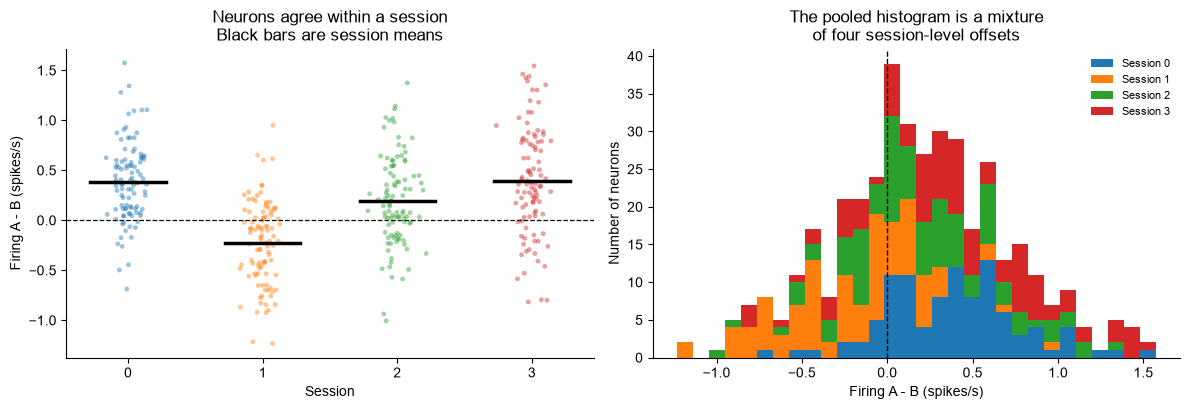

per-session mean A - B  : [ 0.384 -0.226  0.196  0.398]
intraclass correlation  : 0.289
design effect 1+(m-1)ICC: 29.6   (m = 100 neurons per session)
SE understated by factor: 5.44
effective sample size   : 13.5 observations, not 400


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

rng_j = np.random.default_rng(0)
for s in range(n_sessions):
    x = s + rng_j.normal(0, 0.07, n_neurons)
    axes[0].scatter(x, AmB[s], s=12, alpha=0.45, color=SESSION_COLORS[s],
                    edgecolors='none')
    axes[0].plot([s - 0.28, s + 0.28], [AmB[s].mean()] * 2, color='k', lw=2.5)
axes[0].axhline(0.0, color='k', lw=0.9, ls='--')
axes[0].set_xticks(range(n_sessions))
axes[0].set_xlabel('Session')
axes[0].set_ylabel('Firing A - B (spikes/s)')
axes[0].set_title('Neurons agree within a session\nBlack bars are session means')

axes[1].hist([AmB[s] for s in range(n_sessions)], bins=30, stacked=True,
             color=SESSION_COLORS[:n_sessions],
             label=[f'Session {s}' for s in range(n_sessions)])
axes[1].axvline(0.0, color='k', ls='--', lw=1.0)
axes[1].set_xlabel('Firing A - B (spikes/s)')
axes[1].set_ylabel('Number of neurons')
axes[1].set_title('The pooled histogram is a mixture\nof four session-level offsets')
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

# One-way ANOVA decomposition of the neuron-level effect by session
grand = AmB.mean()
ms_between = n_neurons * np.sum((AmB.mean(1) - grand) ** 2) / (n_sessions - 1)
ms_within  = np.sum((AmB - AmB.mean(1, keepdims=True)) ** 2) / (n_sessions * (n_neurons - 1))
icc  = (ms_between - ms_within) / (ms_between + (n_neurons - 1) * ms_within)
deff = 1 + (n_neurons - 1) * icc

print(f'per-session mean A - B  : {np.round(AmB.mean(1), 3)}')
print(f'intraclass correlation  : {icc:.3f}')
print(f'design effect 1+(m-1)ICC: {deff:.1f}   (m = {n_neurons} neurons per session)')
print(f'SE understated by factor: {np.sqrt(deff):.2f}')
print(f'effective sample size   : {flat.size/deff:.1f} observations, not {flat.size}')


## Evidence 2 — What the neurons actually track is the pupil

This step was available all along: pupil diameter was in the data file. Plot
firing against it.

**Left:** the population mean on each trial against that trial's pupil diameter,
one point per trial, colored by session. The relationship is nearly
deterministic, because averaging 100 neurons removes their independent noise and
leaves only the shared signal.

**Right:** the per-neuron correlation with pupil diameter, computed within
session. Every one of the 400 neurons is positive. That is the ingredient that
makes the pseudo-replication bite: a nuisance variable that all neurons share
*and agree on the sign of*. If half the neurons loaded negatively, the
session-level offsets would largely cancel in the population average and the
naive test would be far less badly behaved.


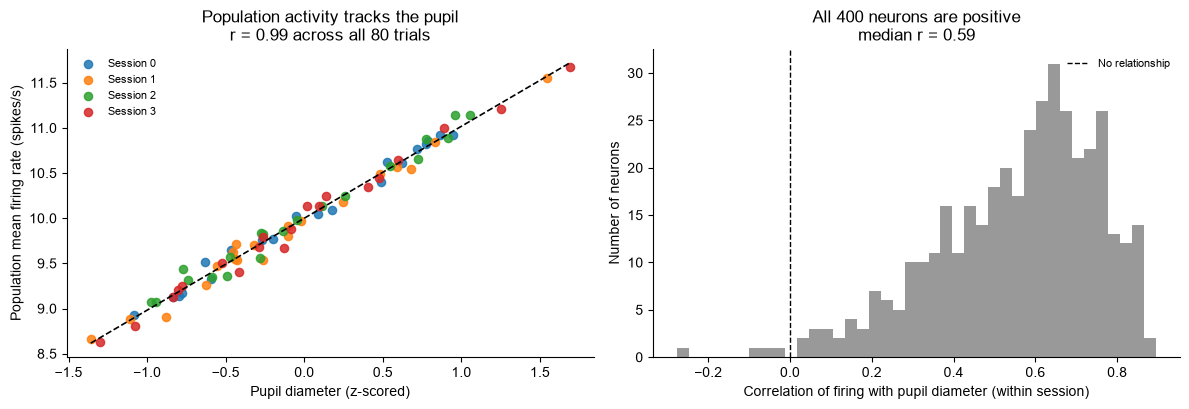

per-neuron correlation with pupil: median 0.591, range -0.276 to 0.895
fraction of neurons with a positive correlation: 99.0%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

for s in range(n_sessions):
    axes[0].scatter(pupil_diameter[s], activity[s].mean(0), s=35,
                    color=SESSION_COLORS[s], alpha=0.85, label=f'Session {s}')
allp = pupil_diameter.ravel()
alla = np.concatenate([activity[s].mean(0) for s in range(n_sessions)])
sl, ic = np.polyfit(allp, alla, 1)
xs = np.linspace(allp.min(), allp.max(), 50)
axes[0].plot(xs, sl * xs + ic, 'k--', lw=1.2)
r_pop = np.corrcoef(allp, alla)[0, 1]
axes[0].set_xlabel('Pupil diameter (z-scored)')
axes[0].set_ylabel('Population mean firing rate (spikes/s)')
axes[0].set_title(f'Population activity tracks the pupil\nr = {r_pop:.2f} across all '
                  f'{allp.size} trials')
axes[0].legend(frameon=False, fontsize=8)

r_each = np.array([[np.corrcoef(activity[s][i], pupil_diameter[s])[0, 1]
                    for i in range(n_neurons)] for s in range(n_sessions)])
axes[1].hist(r_each.ravel(), bins=40, color='0.6')
axes[1].axvline(0.0, color='k', ls='--', lw=1.0, label='No relationship')
axes[1].set_xlabel('Correlation of firing with pupil diameter (within session)')
axes[1].set_ylabel('Number of neurons')
axes[1].set_title(f'All {r_each.size} neurons are positive\n'
                  f'median r = {np.median(r_each):.2f}')
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

print(f'per-neuron correlation with pupil: median {np.median(r_each):.3f}, '
      f'range {r_each.min():.3f} to {r_each.max():.3f}')
print(f'fraction of neurons with a positive correlation: {np.mean(r_each > 0)*100:.1f}%')


## Evidence 3 — Where each session's offset came from

The pupil declines across every session. The A/B labels were shuffled, so in each
session the A trials landed a bit earlier or a bit later than the B trials by
chance. That is the whole mechanism: the mean trial index of the A trials predicts
the sign and size of the session's apparent condition effect.

Nothing here is a property of the conditions. It is a property of where the
shuffle happened to put them.


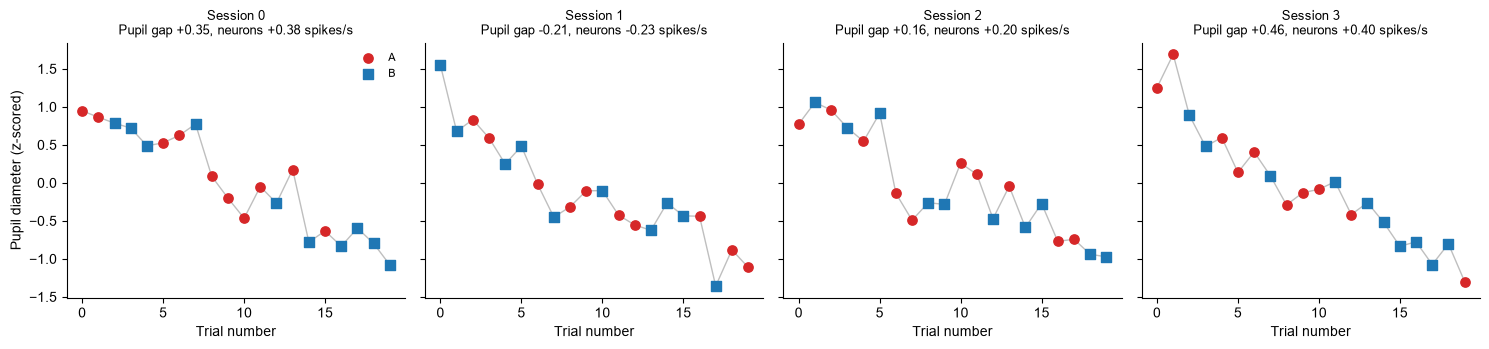

 session  mean A trial  mean B trial   pupil gap   neuron A-B
       0           7.8          11.2      +0.346       +0.384
       1          10.4           8.6      -0.215       -0.226
       2           8.6          10.4      +0.155       +0.196
       3           7.4          11.6      +0.465       +0.398

The sign of the neuron-level effect follows the chance pupil gap exactly.


In [6]:
fig, axes = plt.subplots(1, n_sessions, figsize=(15, 3.6), sharey=True)
for s in range(n_sessions):
    ax = axes[s]
    isA = condition[s] == 1
    trials = np.arange(n_trials)
    ax.plot(trials, pupil_diameter[s], '-', color='0.75', lw=1.0, zorder=1)
    ax.scatter(trials[isA],  pupil_diameter[s][isA],  s=45, color='tab:red',
               label='A', zorder=3)
    ax.scatter(trials[~isA], pupil_diameter[s][~isA], s=45, color='tab:blue',
               marker='s', label='B', zorder=3)
    gap = pupil_diameter[s][isA].mean() - pupil_diameter[s][~isA].mean()
    ax.set_title(f'Session {s}\nPupil gap {gap:+.2f}, '
                 f'neurons {AmB[s].mean():+.2f} spikes/s', fontsize=9)
    ax.set_xlabel('Trial number')
    if s == 0:
        ax.set_ylabel('Pupil diameter (z-scored)')
        ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

print(f'{"session":>8} {"mean A trial":>13} {"mean B trial":>13} '
      f'{"pupil gap":>11} {"neuron A-B":>12}')
for s in range(n_sessions):
    isA = condition[s] == 1
    print(f'{s:8d} {np.mean(np.where(isA)[0]):13.1f} {np.mean(np.where(~isA)[0]):13.1f} '
          f'{pupil_diameter[s][isA].mean() - pupil_diameter[s][~isA].mean():+11.3f} '
          f'{AmB[s].mean():+12.3f}')
print('\nThe sign of the neuron-level effect follows the chance pupil gap exactly.')


## Evidence 4 — Analyses that get it right, including the mixed model

**Session as the unit.** Average within session, then test across the 4 sessions.
The session-to-session spread is now visible and the effect is not significant.

**Permute the labels within session.** This is the assumption-free version.
Reshuffle A/B within each session, recompute the *naive* t-statistic, and repeat.
If the naive t were a valid t-statistic its null distribution would have SD about
1. It does not. That ratio is the pseudo-replication inflation, measured directly.

**Regress out the pupil.** Since the pupil is what the neurons actually track,
removing it within session removes the apparent condition effect. This one needs
you to have measured the confound, which is why the first two matter more.

**A linear mixed-effects model.** This is the tool most people reach for, and it
is the right one, but it is worth being clear about what it does. Fit
`firing ~ condition + (condition | session)`, that is a random intercept and a
random slope for condition per session. For a design as balanced as this one, the
estimate of the condition effect is exactly the mean of the per-session effects,
and its standard error is exactly `SD(per-session effects) / sqrt(n_sessions)`.
That is the session-level t-test, arithmetically identical, as the printout below
confirms.

So a mixed model does not extract more evidence from 4 sessions than 4 sessions
contain. What it buys you is correctness under imbalance (unequal neurons per
session, unequal trials, missing cells) and the ability to model more structure.
What improves as you add sessions is its **power**, not its calibration, which was
already right. One caveat in the other direction: with very few clusters, mixed
models fitted with asymptotic Wald inference are somewhat anti-conservative, which
is exactly why Satterthwaite or Kenward-Roger degrees of freedom matter at n = 4.


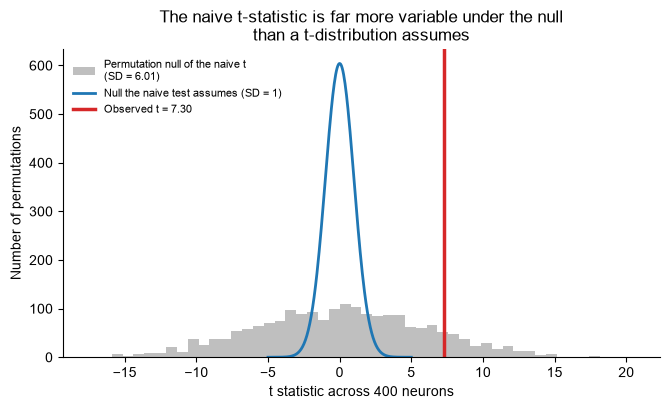

naive, 400 neurons as observations : t =  7.30, p = 1.52e-12
session as the unit (n = 4)        : t =  1.29, p = 0.286
session-wise label permutation     : p = 0.231   (null SD 6.01, not 1)
after regressing out the pupil     : t = -0.23, p = 0.819

On a balanced design the mixed model IS the session-level test:
  estimate  = mean of per-session effects           = +0.1882 spikes/s
  std error = SD(per-session effects)/sqrt(4)       = 0.1454
  t         = estimate / std error                  = 1.2940
  session-level t-test statistic from scipy         = 1.2940   <- identical


In [7]:
# --- 1. session as the unit of analysis ---
session_means = AmB.mean(1)
t_s, p_s = stats.ttest_1samp(session_means, 0.0)

# --- 2. session-wise label permutation null for the naive t ---
N_PERM = 2000
rng_p = np.random.default_rng(0)
null_t = np.empty(N_PERM)
for i in range(N_PERM):
    e = np.empty((n_sessions, n_neurons))
    for s in range(n_sessions):
        c = condition[s].copy()
        rng_p.shuffle(c)
        e[s] = (activity[s][:, c == 1].mean(1) - activity[s][:, c == -1].mean(1))
    null_t[i] = stats.ttest_1samp(e.ravel(), 0.0).statistic
p_perm = (np.sum(np.abs(null_t) >= abs(t_naive)) + 1) / (N_PERM + 1)

# --- 3. regress the pupil out within session ---
resid = np.zeros((n_sessions, n_neurons))
for s in range(n_sessions):
    X = np.column_stack([np.ones(n_trials), pupil_diameter[s]])
    coef, *_ = np.linalg.lstsq(X, activity[s].T, rcond=None)
    r = activity[s].T - X @ coef
    resid[s] = r[condition[s] == 1].mean(0) - r[condition[s] == -1].mean(0)
t_r, p_r = stats.ttest_1samp(resid.ravel(), 0.0)

fig, ax = plt.subplots(figsize=(6.8, 4.2))
ax.hist(null_t, bins=50, color='0.75',
        label=f'Permutation null of the naive t\n(SD = {null_t.std():.2f})')
xs = np.linspace(-5, 5, 200)
ax.plot(xs, stats.t.pdf(xs, df=flat.size - 1) * N_PERM * (null_t.max()-null_t.min())/50,
        color='tab:blue', lw=2, label='Null the naive test assumes (SD = 1)')
ax.axvline(t_naive, color='tab:red', lw=2.5, label=f'Observed t = {t_naive:.2f}')
ax.set_xlabel('t statistic across 400 neurons')
ax.set_ylabel('Number of permutations')
ax.set_title('The naive t-statistic is far more variable under the null\n'
             'than a t-distribution assumes')
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

print(f'naive, 400 neurons as observations : t = {t_naive:5.2f}, p = {p_naive:.2e}')
print(f'session as the unit (n = {n_sessions})        : t = {t_s:5.2f}, p = {p_s:.3f}')
print(f'session-wise label permutation     : p = {p_perm:.3f}   '
      f'(null SD {null_t.std():.2f}, not 1)')
print(f'after regressing out the pupil     : t = {t_r:5.2f}, p = {p_r:.3f}')

# The balanced-design identity: random-slope LME == session-level t-test
est = session_means.mean()
se  = session_means.std(ddof=1) / np.sqrt(n_sessions)
print(f'\nOn a balanced design the mixed model IS the session-level test:')
print(f'  estimate  = mean of per-session effects           = {est:+.4f} spikes/s')
print(f'  std error = SD(per-session effects)/sqrt({n_sessions})       = {se:.4f}')
print(f'  t         = estimate / std error                  = {est/se:.4f}')
print(f'  session-level t-test statistic from scipy         = {t_s:.4f}   <- identical')


## Evidence 5 — The false positive rate, measured, and why more sessions never help

The definitive test of a method is to run it many times on data where you know the
answer. Simulate the whole experiment 1000 times from the same generative model,
which has no condition effect, and count how often each analysis declares one.

Then two sweeps, because the scaling is the surprising part. It is tempting to
assume this is a small-sample problem that 100 or 1000 sessions would cure. It is
not. Write each neuron's effect as `load * d_s + noise`, where `d_s` is the
session's chance pupil gap, **shared** by all `N` neurons recorded together, and
`noise` is independent per neuron. Then across `S` sessions:

- the **numerator** of the naive t, the mean over all `S*N` neurons, is essentially
  the mean of the `S` session gaps, so its SD shrinks as `1/sqrt(S)`;
- the **denominator**, the across-neuron SD divided by `sqrt(S*N)`, shrinks as
  `1/sqrt(S*N)`, because the across-neuron SD itself does not shrink with `S` at
  all. It converges to a constant.

The `sqrt(S)` cancels exactly. What survives is

> `SD of the naive t under the null  =  sqrt(N) * sigma_shared / sigma_total`

which depends on the number of neurons **per session** and not at all on the
number of sessions. Here that is `sqrt(100) * 0.309 / 0.550 = 5.6`, which is the
permutation null SD of about 6 that we measured directly in Evidence 4.

So the false positive rate is flat in the number of sessions, out as far as you
care to go. What does control it is cluster size, and the limiting case is a good
check on the whole argument: at **one** neuron per session there is no
pseudo-replication, neurons and sessions are the same thing, and the naive test is
exactly calibrated at 5%.


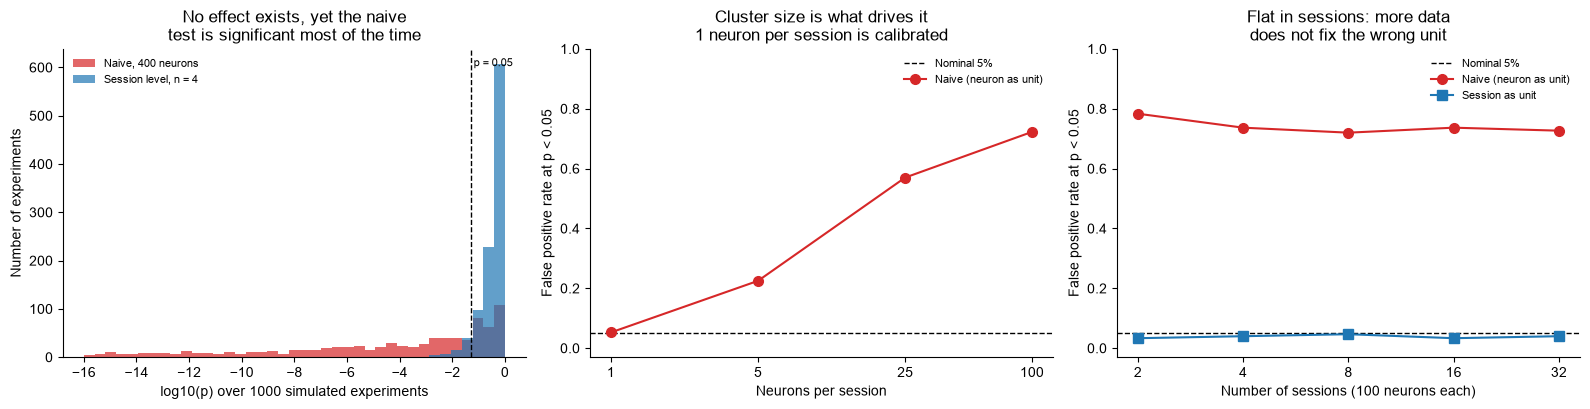

over 1000 experiments with no condition effect whatsoever:
  naive p < 0.05   :  73.4%
  naive p < 0.001  :  58.3%
  session p < 0.05 :   5.9%   <- nominal
  of the naive hits at p < 0.05, 49% favored A (a coin flip)

naive false positive rate at p < 0.05, by neurons per session:
     1 neurons/session (    4 total):   5.2%
     5 neurons/session (   20 total):  22.5%
    25 neurons/session (  100 total):  57.0%
   100 neurons/session (  400 total):  72.2%

naive false positive rate at p < 0.05, by number of sessions:
    2 sessions (  200 neurons):  78.3%
    4 sessions (  400 neurons):  73.7%
    8 sessions (  800 neurons):  72.0%
   16 sessions ( 1600 neurons):  73.7%
   32 sessions ( 3200 neurons):  72.7%

positive control, session-level test with a REAL condition effect:


  true effect 0.0 spikes/s -> detected in   5.7% of experiments


  true effect 0.5 spikes/s -> detected in  56.7% of experiments


  true effect 1.0 spikes/s -> detected in  98.7% of experiments


  true effect 1.5 spikes/s -> detected in 100.0% of experiments


In [8]:
def simulate(rng, n_sess, n_neur=100, n_tr=20, true_effect=0.0):
    """One whole experiment from the same generative model -> (sessions, neurons)."""
    ramp = 1.0 - 2.0 * np.arange(n_tr) / (n_tr - 1)
    out = np.empty((n_sess, n_neur))
    for s in range(n_sess):
        p = rng.uniform(0.7, 1.3) * ramp + rng.normal(0, 0.3, n_tr)
        c = np.repeat([1, -1], n_tr // 2); rng.shuffle(c)
        load = rng.uniform(0.5, 1.5, n_neur)
        fr = (10.0 + load[:, None] * p[None, :]
              + true_effect * (c == 1)[None, :]
              + rng.normal(0, 1.0, (n_neur, n_tr)))
        out[s] = fr[:, c == 1].mean(1) - fr[:, c == -1].mean(1)
    return out

def both_tests(e):
    return (stats.ttest_1samp(e.ravel(), 0.0),
            stats.ttest_1samp(e.mean(1), 0.0))

# --- 1000 replications of OUR design (4 sessions x 100 neurons) ---
N_REP = 1000
rng_s = np.random.default_rng(1)
sim_t = np.empty(N_REP); pn = np.empty(N_REP); ps = np.empty(N_REP)
splits = np.empty(N_REP)
for i in range(N_REP):
    e = simulate(rng_s, n_sessions)
    rn, rs = both_tests(e)
    sim_t[i], pn[i], ps[i] = rn.statistic, rn.pvalue, rs.pvalue
    splits[i] = np.sum(e.mean(1) > 0)

# --- sweep neurons per session, sessions fixed at 4 ---
neur_grid = [1, 5, 25, 100]
fpr_by_neur = []
for nn in neur_grid:
    rng_c = np.random.default_rng(2)
    fpr_by_neur.append(np.mean([both_tests(simulate(rng_c, n_sessions, n_neur=nn))[0].pvalue
                                < 0.05 for _ in range(400)]))

# --- sweep sessions, neurons per session fixed at 100 ---
sess_grid = [2, 4, 8, 16, 32]
fpr_naive, fpr_sess = [], []
for ns in sess_grid:
    rng_c = np.random.default_rng(3)
    a, b = [], []
    for _ in range(300):
        rn, rs = both_tests(simulate(rng_c, ns))
        a.append(rn.pvalue < 0.05); b.append(rs.pvalue < 0.05)
    fpr_naive.append(np.mean(a)); fpr_sess.append(np.mean(b))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

bins = np.linspace(-16, 0, 40)
axes[0].hist(np.log10(pn), bins=bins, color='tab:red', alpha=0.7,
             label=f'Naive, {n_sessions*n_neurons} neurons')
axes[0].hist(np.log10(ps), bins=bins, color='tab:blue', alpha=0.7,
             label=f'Session level, n = {n_sessions}')
axes[0].axvline(np.log10(0.05), color='k', ls='--', lw=1.0)
axes[0].text(np.log10(0.05), axes[0].get_ylim()[1]*0.97, ' p = 0.05',
             fontsize=8, va='top')
axes[0].set_xlabel('log10(p) over 1000 simulated experiments')
axes[0].set_ylabel('Number of experiments')
axes[0].set_title('No effect exists, yet the naive\ntest is significant most of the time')
axes[0].legend(frameon=False, fontsize=8)

axes[1].axhline(0.05, color='k', ls='--', lw=1.0, label='Nominal 5%')
axes[1].plot(neur_grid, fpr_by_neur, 'o-', color='tab:red', ms=7,
             label='Naive (neuron as unit)')
axes[1].set_xscale('log'); axes[1].set_ylim(-0.03, 1.0)
axes[1].set_xticks(neur_grid); axes[1].set_xticklabels(neur_grid)
axes[1].minorticks_off()
axes[1].set_xlabel('Neurons per session')
axes[1].set_ylabel('False positive rate at p < 0.05')
axes[1].set_title('Cluster size is what drives it\n'
                  '1 neuron per session is calibrated')
axes[1].legend(frameon=False, fontsize=8)

axes[2].axhline(0.05, color='k', ls='--', lw=1.0, label='Nominal 5%')
axes[2].plot(sess_grid, fpr_naive, 'o-', color='tab:red', ms=7,
             label='Naive (neuron as unit)')
axes[2].plot(sess_grid, fpr_sess, 's-', color='tab:blue', ms=7,
             label='Session as unit')
axes[2].set_xscale('log'); axes[2].set_ylim(-0.03, 1.0)
axes[2].set_xticks(sess_grid); axes[2].set_xticklabels(sess_grid)
axes[2].minorticks_off()
axes[2].set_xlabel('Number of sessions (100 neurons each)')
axes[2].set_ylabel('False positive rate at p < 0.05')
axes[2].set_title('Flat in sessions: more data\ndoes not fix the wrong unit')
axes[2].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

print(f'over {N_REP} experiments with no condition effect whatsoever:')
print(f'  naive p < 0.05   : {np.mean(pn < 0.05)*100:5.1f}%')
print(f'  naive p < 0.001  : {np.mean(pn < 0.001)*100:5.1f}%')
print(f'  session p < 0.05 : {np.mean(ps < 0.05)*100:5.1f}%   <- nominal')
print(f'  of the naive hits at p < 0.05, {np.mean(sim_t[pn < 0.05] > 0)*100:.0f}% '
      f'favored A (a coin flip)')

print(f'\nnaive false positive rate at p < 0.05, by neurons per session:')
for nn, f in zip(neur_grid, fpr_by_neur):
    print(f'  {nn:4d} neurons/session ({nn*n_sessions:5d} total): {f*100:5.1f}%')
print(f'\nnaive false positive rate at p < 0.05, by number of sessions:')
for ns, f in zip(sess_grid, fpr_naive):
    print(f'  {ns:3d} sessions ({ns*100:5d} neurons): {f*100:5.1f}%')

print('\npositive control, session-level test with a REAL condition effect:')
for eff in (0.0, 0.5, 1.0, 1.5):
    rng_e = np.random.default_rng(4)
    hit = [stats.ttest_1samp(simulate(rng_e, n_sessions, true_effect=eff).mean(1),
                             0.0).pvalue < 0.05 for _ in range(300)]
    print(f'  true effect {eff:.1f} spikes/s -> detected in {np.mean(hit)*100:5.1f}% '
          f'of experiments')


## Evidence 6 — This dataset is an unremarkable draw, not a hunted seed

A fair objection to everything above: the dataset was generated with a fixed seed,
so perhaps the seed was hunted for until it produced p = 2e-12. That objection
applies to *any* single demonstration, including one built on a perfectly valid
test, which is precisely why the argument has to rest on the **rate** rather than
on this one dataset. Given enough seeds you could find a striking figure under a
correct analysis too.

So place the observed statistic in the distribution the model actually produces.
It lands near the 74th percentile of |t|: about a quarter of experiments from this
generative model give a naive t at least this extreme. And the 3-to-1 session split
that makes the figures legible is the single most common outcome, at roughly half
of all experiments, with a unanimous 4-0 split happening about one time in eight.

The seed was chosen for legibility, not for significance. That distinction is the
whole point: an analysis that is wrong 58% of the time does not need a lucky seed.


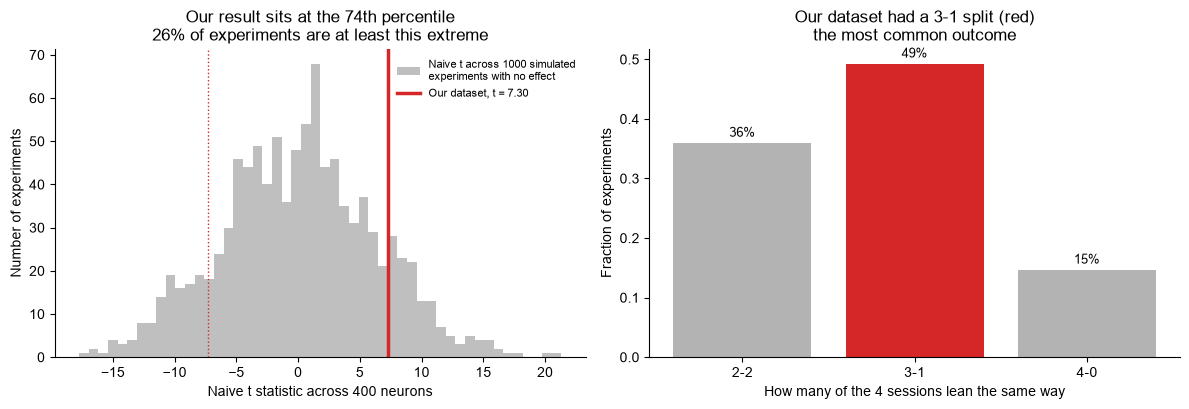

our observed naive t                    : 7.30
percentile among 1000 null experiments  : 74th
experiments with |t| at least this large: 25.5%
our session split                       : 3-1  (occurs 49% of the time)


In [9]:
t_obs = t_naive
frac_extreme = np.mean(np.abs(sim_t) >= abs(t_obs))
pctile = stats.percentileofscore(np.abs(sim_t), abs(t_obs))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(sim_t, bins=50, color='0.75',
             label='Naive t across 1000 simulated\nexperiments with no effect')
axes[0].axvline(t_obs, color='tab:red', lw=2.5,
                label=f'Our dataset, t = {t_obs:.2f}')
axes[0].axvline(-t_obs, color='tab:red', lw=1.0, ls=':')
axes[0].set_xlabel('Naive t statistic across 400 neurons')
axes[0].set_ylabel('Number of experiments')
axes[0].set_title(f'Our result sits at the {pctile:.0f}th percentile\n'
                  f'{frac_extreme*100:.0f}% of experiments are at least this extreme')
axes[0].legend(frameon=False, fontsize=8)

same_side = np.maximum(splits, n_sessions - splits).astype(int)
labels = [f'{k}-{n_sessions-k}' for k in range(n_sessions//2, n_sessions + 1)]
heights = [np.mean(same_side == k) for k in range(n_sessions//2, n_sessions + 1)]
obs_split = int(max(np.sum(AmB.mean(1) > 0), n_sessions - np.sum(AmB.mean(1) > 0)))
colors = ['tab:red' if int(l.split('-')[0]) == obs_split else '0.7' for l in labels]
axes[1].bar(labels, heights, color=colors)
axes[1].set_xlabel('How many of the 4 sessions lean the same way')
axes[1].set_ylabel('Fraction of experiments')
axes[1].set_title(f'Our dataset had a {obs_split}-{n_sessions-obs_split} split (red)\n'
                  f'the most common outcome')
for x, h in zip(labels, heights):
    axes[1].text(x, h + 0.01, f'{h*100:.0f}%', ha='center', fontsize=9)
plt.tight_layout(); plt.show()

print(f'our observed naive t                    : {t_obs:.2f}')
print(f'percentile among 1000 null experiments  : {pctile:.0f}th')
print(f'experiments with |t| at least this large: {frac_extreme*100:.1f}%')
print(f'our session split                       : {obs_split}-{n_sessions-obs_split}'
      f'  (occurs {np.mean(same_side == obs_split)*100:.0f}% of the time)')


## Ground truth


In [10]:
gt = np.load('data/ground_truth.npz', allow_pickle=True)
print('realized chance pupil gap per session:', np.round(gt['pupil_gap'], 3))
print('all pupil loadings positive:', bool(np.all(gt['loadings'] > 0)),
      f"(range {gt['loadings'].min():.2f} to {gt['loadings'].max():.2f})")
print()
print(str(gt['note']))


realized chance pupil gap per session: [ 0.346 -0.215  0.155  0.465]
all pupil loadings positive: True (range 0.50 to 1.50)

There is NO condition term in the generative model: activity = base + loading*pupil_diameter + noise, and the A/B labels are a random balanced permutation independent of pupil diameter. The marginal A-vs-B difference is exactly zero in expectation. In each session the A trials happened to land earlier or later than the B trials, which under a declining pupil trend gives that session a chance pupil gap that every neuron in it inherits.


## The lesson

- **p-values assume independent observations, and simultaneously recorded neurons
  are not independent.** They share arousal, pupil, movement, drift, and
  everything else about the moment they were recorded in. Counting each as a
  separate observation understates the standard error by
  `sqrt(1 + (m-1) * ICC)`, which here is a factor of about 5.

- **The unit of analysis is the unit you could have independently repeated.** That
  is the session or the animal, not the neuron. Summarize within unit and test
  across units, or fit a mixed-effects model with a per-session random effect. If
  that leaves you with n = 4, the honest conclusion is that you cannot establish
  the effect, not that you should count neurons instead.

- **A mixed model is the right tool but not a loophole.** On a balanced design it
  is arithmetically the session-level test. It earns its keep under imbalance and
  when you want to model more structure, and its power grows with sessions, but it
  will not manufacture evidence that 4 sessions do not contain.

- **More data makes it worse, not better.** The naive false positive rate was flat
  at about 73% from 2 sessions to 32, and it *rises* with neurons per session: 5%
  at one neuron per session, 23% at 5, 57% at 25, 72% at 100. Pseudo-replication
  is not a small-sample problem that more data cures; it is the wrong variance
  estimate, and every extra neuron in the same session sharpens a conclusion you
  have no more evidence for. This is the uncomfortable part of high-density
  recording: probe channel count grows much faster than session count.

- **A random sign is the signature.** A real effect has a direction that
  replicates. If rerunning the experiment would flip the answer half the time, you
  are looking at a shared nuisance, not a code. Permuting the condition labels
  within session is the cheapest way to check, because it builds the null from the
  same correlated structure your data has.

- **Measure your nuisance variables.** The pupil trace was sitting in the data
  file the whole time, and one scatter plot would have shown what the neurons were
  really tracking. It matters that all the loadings had the same sign: a shared
  nuisance that neurons disagree about the sign of largely cancels in the
  population average.

- **Beware anything that turns one measurement into many.** The same bias appears
  when the repeated unit is a voxel, a trial, a cell in a dish from one culture, a
  pup from one litter, or a timepoint in a smoothed trace.
